# Workshop 3 — Gold Layer Preview
**Team 4 · Tropical Cyclone Monitoring (TC-Analog Monitor) · Data Analysis Programming**

The `gold_processing` DAG reads all of `datalake_silver/` with PySpark (local mode) and writes two tidy tables:

* `datalake_gold/governance_YYYYMMDD_HHMMSS.parquet` — data-governance KPIs (one row per KPI value);
* `datalake_gold/storytelling_YYYYMMDD_HHMMSS.parquet` — the story of every current storm and its historical analogs.

This notebook opens the **latest** pair with Pandas and turns them into the views the dashboard will show in
Workshop 4. The last cell reads the same folder with PySpark.

**How to run**
```bash
docker compose exec airflow-scheduler jupyter nbconvert --to notebook --execute --inplace /opt/airflow/notebooks/04_gold_preview.ipynb
```

In [1]:
import os
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("TCMON_DATALAKE_ROOT", str(ROOT))
from tcmon.pipeline import paths

GOLD = paths.gold_dir()
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
STATUS_COLORS = {"ok": "#2e8b57", "warn": "#e0a31f", "fail": "#c0392b", "info": "#9aa5b1", "n/a": "#d5dbe1"}

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, bbox_inches="tight"); plt.show()

gov_files = sorted(GOLD.glob("governance_*.parquet"))
story_files = sorted(GOLD.glob("storytelling_*.parquet"))
print(f"{len(gov_files)} governance and {len(story_files)} storytelling files in {GOLD}")
pd.DataFrame([{"file": f.name, "KB": round(f.stat().st_size / 1024, 1), "rows": len(pd.read_parquet(f))}
              for f in (gov_files[-3:] + story_files[-3:])])

18 governance and 16 storytelling files in /opt/airflow/datalake_gold


,file,KB,rows
0,governance_20261120_094000.parquet,9.5,144
1,governance_20261121_034000.parquet,9.6,149
2,governance_20261121_040036.parquet,9.6,149
3,storytelling_20261120_094000.parquet,23.9,1431
4,storytelling_20261121_034000.parquet,19.0,1003
5,storytelling_20261121_040036.parquet,19.0,1003


In [2]:
gov = pd.read_parquet(gov_files[-1])
story = pd.read_parquet(story_files[-1])
story["rank"] = story["rank"].astype("Int64")
story["storm_name"] = story["storm_name"].fillna(story["storm_id"])   # unnamed storms are shown by their SID
print("Governance :", gov_files[-1].name, gov.shape)
print("Storytelling:", story_files[-1].name, story.shape)
print(gov.dtypes.to_string())

Governance : governance_20261121_040036.parquet (149, 14)
Storytelling: storytelling_20261121_040036.parquet (1003, 17)
kpi_id                          object
dimension                       object
kpi_name                        object
scope                           object
scope_value                     object
value                          float64
unit                            object
target                          object
status                          object
basis_n                        float64
detail                          object
user_story                      object
gold_run_ts                     object
computed_at_utc    datetime64[us, UTC]


## 1. Governance KPIs
Status: **ok** meets the target, **warn** is close, **fail** misses it, **info** has no target (descriptive).

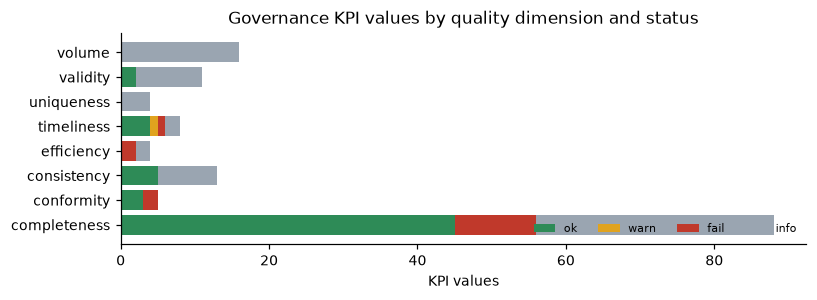

status,ok,warn,fail,info
dimension,,,,
completeness,45,0,11,32
conformity,3,0,2,0
consistency,5,0,0,8
efficiency,0,0,2,2
timeliness,4,1,1,2
uniqueness,0,0,0,4
validity,2,0,0,9
volume,0,0,0,16


In [3]:
counts = gov.groupby(["dimension", "status"]).size().unstack(fill_value=0)
counts = counts[[c for c in ["ok", "warn", "fail", "info", "n/a"] if c in counts.columns]]
fig, ax = plt.subplots(figsize=(7.5, 2.8))
left = np.zeros(len(counts))
for st in counts.columns:
    ax.barh(counts.index, counts[st], left=left, color=STATUS_COLORS[st], label=st); left += counts[st].to_numpy()
ax.set_xlabel("KPI values"); ax.legend(fontsize=7, frameon=False, ncol=5, loc="lower right")
ax.set_title("Governance KPI values by quality dimension and status")
save(fig, "g1_kpi_status.png")
counts

In [4]:
headline = gov[gov.kpi_id != "C1"][["kpi_id", "dimension", "kpi_name", "scope_value", "value", "unit", "target", "status",
                                     "basis_n", "detail"]]
headline.assign(value=headline.value.round(2))

,kpi_id,dimension,kpi_name,scope_value,value,unit,target,status,basis_n,detail
76,C2,completeness,Hourly ingestion slots covered per day,gdacs_tc/2026-11-17,16.67,%,>= 95,fail,4.0,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
77,C2,completeness,Hourly ingestion slots covered per day,gdacs_tc/2026-11-18,20.83,%,>= 95,fail,5.0,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
78,C2,completeness,Hourly ingestion slots covered per day,gdacs_tc/2026-11-19,16.67,%,>= 95,fail,4.0,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
79,C2,completeness,Hourly ingestion slots covered per day,gdacs_tc/2026-11-20,45.83,%,>= 95,fail,11.0,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
80,C2,completeness,Hourly ingestion slots covered per day,gdacs_tc/2026-11-21,4.17,%,>= 95,fail,1.0,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
...,...,...,...,...,...,...,...,...,...,...
144,V7,validity,Provisional track fixes (will be revised by the agency),ibtracs_active,100.00,%,None,info,201.0,None
145,V8,validity,Spur track fixes (excluded from analogs),ibtracs_active,0.00,%,None,info,201.0,None
146,V9,validity,Silver runs per outlier-fence basis,batch,2.00,runs,None,info,2.0,'reference' = 1980-2025 climatology; 'batch' = fence computed inside the batch
147,V9,validity,Silver runs per outlier-fence basis,batch (Workshop 2),12.00,runs,None,info,12.0,'reference' = 1980-2025 climatology; 'batch' = fence computed inside the batch


### Issues to act on (fail / warn)

In [5]:
gov[gov.status.isin(["fail", "warn"])][["kpi_id", "kpi_name", "scope_value", "value", "unit", "target", "status", "detail"]]

,kpi_id,kpi_name,scope_value,value,unit,target,status,detail
76,C2,Hourly ingestion slots covered per day,gdacs_tc/2026-11-17,16.666667,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
77,C2,Hourly ingestion slots covered per day,gdacs_tc/2026-11-18,20.833333,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
78,C2,Hourly ingestion slots covered per day,gdacs_tc/2026-11-19,16.666667,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
79,C2,Hourly ingestion slots covered per day,gdacs_tc/2026-11-20,45.833333,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
80,C2,Hourly ingestion slots covered per day,gdacs_tc/2026-11-21,4.166667,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
81,C2,Hourly ingestion slots covered per day,ibtracs_active/2026-11-17,16.666667,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
82,C2,Hourly ingestion slots covered per day,ibtracs_active/2026-11-18,20.833333,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
83,C2,Hourly ingestion slots covered per day,ibtracs_active/2026-11-19,16.666667,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
84,C2,Hourly ingestion slots covered per day,ibtracs_active/2026-11-20,45.833333,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)
85,C2,Hourly ingestion slots covered per day,ibtracs_active/2026-11-21,8.333333,%,>= 95,fail,distinct hours with a successful extraction / 24 (days with the stack off count as gaps)


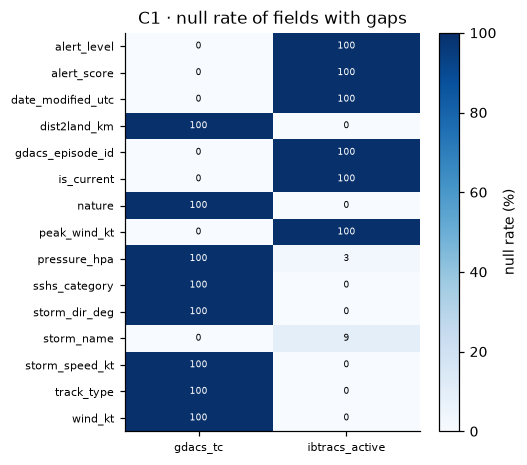

In [6]:
c1 = gov[gov.kpi_id == "C1"].copy()
c1[["source", "field"]] = c1["scope_value"].str.split("/", n=1, expand=True)
heat = c1.pivot_table(index="field", columns="source", values="value").loc[lambda d: d.max(axis=1) > 0]
fig, ax = plt.subplots(figsize=(4.8, 0.22 * len(heat) + 1))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_yticks(range(len(heat)), heat.index, fontsize=7); ax.set_xticks(range(heat.shape[1]), heat.columns, fontsize=7)
for (i, j), v in np.ndenumerate(heat.to_numpy()):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6, color="white" if v > 50 else "black")
fig.colorbar(im, ax=ax, label="null rate (%)"); ax.set_title("C1 · null rate of fields with gaps")
save(fig, "g2_null_heatmap.png")

## 2. Storytelling
Every row is one fact about a storm; `section` and `user_story` link it to the Workshop 1 user stories.

In [7]:
story.groupby(["section", "user_story"]).agg(rows=("metric", "size"), storms=("storm_id", "nunique"),
                                             metrics=("metric", lambda s: ", ".join(sorted(set(s))[:6])))

,,rows,storms,metrics
section,user_story,,,
analog_outcomes,US-03/US-05,150,3,"analogs_intensifying_48h, analogs_tracked_48h_after_match, analogs_weakening_48h, anal..."
analog_tracks,US-05,319,3,track_point
analogs,US-03,147,3,"analog_lifetime_max_wind_kt, analog_wind_at_match_kt, analogs_found, best_sas, current..."
basin_climatology,US-08,15,3,"current_max_wind_percentile_in_basin, median_lifetime_max_wind_kt, share_active_in_cur..."
current_status,US-01/US-06,39,3,"dist2land_km, fixes, gdacs_alert, gdacs_peak_wind_kt, is_provisional, max_wind_so_far_kt"
gdacs_alerts,US-01/US-02,28,4,"alert_score, peak_wind_kt"
intensity_track,US-05,278,3,"pressure_hpa, wind_kt"
narrative,all,3,3,summary
source_comparison,US-04,16,4,"gdacs_lead_h, gdacs_peak_wind_kt, ibtracs_max_wind_kt, peak_difference_kt"


### 2.1 Current storms (US-01, US-06)

In [8]:
cs = story[story.section == "current_status"]
wide = cs.pivot_table(index=["storm_name", "basin", "storm_id"], columns="metric", values="value", aggfunc="first")
text = cs.pivot_table(index=["storm_name", "basin", "storm_id"], columns="metric", values="value_text", aggfunc="first")
last_fix = cs.groupby(["storm_name", "basin", "storm_id"])[["timestamp_utc", "latitude", "longitude"]].first()
view = last_fix.join(wide[[c for c in ["wind_kt", "pressure_hpa", "storm_speed_kt", "storm_dir_deg", "gdacs_peak_wind_kt",
                                        "max_wind_so_far_kt"] if c in wide]])
view = view.join(text[[c for c in ["sshs_category", "gdacs_alert", "status"] if c in text]], rsuffix="_txt")
view.round(1)

,,,timestamp_utc,latitude,longitude,wind_kt,pressure_hpa,storm_speed_kt,storm_dir_deg,gdacs_peak_wind_kt,max_wind_so_far_kt,sshs_category,gdacs_alert,status
storm_name,basin,storm_id,,,,,,,,,,,,
AKVAN,NI,2026321N11087,2026-11-19 12:00:00+00:00,16.0,85.3,35.0,1002.0,10.0,5.0,45.0,45.0,tropical storm,Green,active (GDACS current)
PENA,EP,2026307N08230,2026-11-12 12:00:00+00:00,9.8,-173.2,30.0,1006.0,20.0,270.0,50.0,50.0,tropical depression,Green,not current in GDACS
XAVIER,SP,2026319S08201,2026-11-19 12:00:00+00:00,-10.6,-163.1,105.0,952.0,1.0,80.0,130.0,128.0,Category 3,Green,active (GDACS current)


### 2.2 Narrative per storm (all user stories)

In [9]:
for _, r in story[story.section == "narrative"].iterrows():
    print(textwrap.fill(r["value_text"], 130), "\n")

PENA (Eastern North Pacific): last best-track fix 12 Nov 12:00 UTC at 9.8°N 173.2°W, 30 kt (tropical depression, 1-min wind). It
was moving W at 20 kt. GDACS alert Green (episode 24, peak 50 kt), not current in GDACS. Closest historical analog: UNNAMED (1997)
with SAS 55 (moderate); mean track separation 169 km over the last 48 h, wind difference 11 kt, 11 days apart in the season. Other
analogs: PAKA (1997) 45, OWEN (1990) 43, SKIP (1985) 35, HATTIE (1993) 35. Of the 4 analogs still tracked 48 h after their
matching point, 2 had intensified and 2 had weakened (median change -5 kt); 0 of 5 reached land within 72 h. Its peak so far is at
or above the lifetime maximum of 44% of the basin's storms since 1980. Analogs describe resemblance with past storms; they are not
a forecast. 

XAVIER (South Pacific): last best-track fix 19 Nov 12:00 UTC at 10.6°S 163.1°W, 105 kt (Category 3, 1-min wind). It was moving E
at 1 kt. GDACS alert Green (episode 15, peak 130 kt), active (GDACS current). Clo

### 2.3 Top-5 historical analogs (US-03) — the core of the story
SAS = 100·e^(−D); D averages the normalized track distance, wind difference, heading difference and day-of-year
difference over the last 48 h. Bands: ≥ 70 high, 40–69 moderate, < 40 low.

In [10]:
an = story[(story.section == "analogs") & (story.item_id != "TOP5")]
if an.empty:
    print("No analogs in this run (reference archive missing, or no historical storm within 300 km).")
else:
    tab = an.pivot_table(index=["storm_name", "rank", "item_name"], columns="metric", values="value", aggfunc="first")
    tab["band"] = an[an.metric == "sas"].set_index(["storm_name", "rank", "item_name"])["value_text"]
    cols = ["sas", "band", "mean_track_km", "mean_abs_dwind_kt", "mean_abs_dheading_deg", "doy_difference_days",
            "analog_wind_at_match_kt", "analog_lifetime_max_wind_kt"]
    display(tab[[c for c in cols if c in tab]].round(1))
    out = story[(story.section == "analog_outcomes") & (story.item_id != "TOP5")]
    if len(out):
        o = out.pivot_table(index=["storm_name", "rank", "item_name"], columns="metric", values="value", aggfunc="first")
        display(o[[c for c in ["dwind_24h_kt", "dwind_48h_kt", "dwind_72h_kt", "max_wind_72h_kt", "min_dist2land_72h_km",
                               "landfall_72h"] if c in o]].round(1))

metric                           sas      band  mean_track_km  mean_abs_dwind_kt  mean_abs_dheading_deg  doy_difference_days  analog_wind_at_match_kt  analog_lifetime_max_wind_kt
storm_name rank item_name                                                                                                                                                         
AKVAN      1    UNNAMED (2002)  65.9  moderate          212.6                1.0                   24.8                  6.0                     35.0                         45.0
           2    UNNAMED (1981)  58.6  moderate           74.0               10.4                   22.9                 19.0                     60.0                         75.0
           3    JAWAD (2021)    57.2  moderate          137.2                6.3                   34.2                 15.0                     35.0                         35.0
           4    UNNAMED (1996)  54.8  moderate           71.8                8.8                   36.1                 22.0                     45.0                         45.0
           5    HELEN (2013)    52.3  moderate          188.9               11.3                   47.2                  1.0                     50.0                         70.0
PENA       1    UNNAMED (1997)  54.9  moderate          168.5               11.1                   27.7                 11.0                     20.0                         35.0
           2    PAKA (1997)     45.5  moderate          353.1                8.9                   20.1                 21.0                     55.0                        160.0
           3    OWEN (1990)     42.7  moderate          332.0               21.7                   22.3                  4.0                     15.0                        140.0
           4    SKIP (1985)     35.0       low          202.9                5.0                   26.4                 74.0                     25.0                         80.0
           5    HATTIE (1993)   34.7       low          403.2               18.9                   17.6                 29.0                     20.0                         50.0
XAVIER     1    MARTIN (1998)   28.8       low          146.4               48.1                   27.8                 17.0                     80.0                        100.0
           2    PERCY (2005)    17.9       low          377.1                6.3                   70.3                102.0                    110.0                        140.0
           3    PAM (1998)      17.6       low          353.3               54.8                   57.6                 18.0                     65.0                         65.0
           4    WILLIAM (1995)   9.3       low          349.4               86.4                   41.2                 43.0                     35.0                         65.0
           5    DOVI (2003)      8.8       low         1143.9               13.4                   67.7                 82.0                    105.0                        130.0

metric                          dwind_24h_kt  dwind_48h_kt  dwind_72h_kt  max_wind_72h_kt  min_dist2land_72h_km  landfall_72h
storm_name rank item_name                                                                                                    
AKVAN      1    UNNAMED (2002)           0.0          -5.0         -10.0             35.0                 211.0           0.0
           2    UNNAMED (1981)          15.0         -10.0           NaN             75.0                   0.0           1.0
           3    JAWAD (2021)           -10.0         -25.0           NaN             35.0                   0.0           1.0
           4    UNNAMED (1996)           0.0         -20.0           NaN             45.0                   0.0           1.0
           5    HELEN (2013)            20.0           5.0         -30.0             70.0                   0.0           1.0
PENA       2    PAKA (1997)             -5.0         -10.0         -20.0             55.0                1771.0           0.0
           3    OWEN (1990)              5.0           5.0           5.0             20.0                2136.0           0.0
           4    SKIP (1985)             15.0          35.0          25.0             70.0                2144.0           0.0
           5    HATTIE (1993)            0.0          -5.0           0.0             20.0                1948.0           0.0
XAVIER     1    MARTIN (1998)           15.0          -5.0         -45.0            100.0                1340.0           0.0
           2    PERCY (2005)            30.0          15.0         -35.0            140.0                 767.0           0.0
           3    PAM (1998)              -5.0         -15.0         -35.0             60.0                1198.0           0.0
           4    WILLIAM (1995)          20.0          20.0           5.0             65.0                1125.0           0.0
           5    DOVI (2003)            -55.0         -55.0         -70.0             95.0                1093.0           0.0

### 2.4 Current track over the analog tracks (US-05)
Left: positions (the current storm in black, analogs coloured by rank; circles mark the matching point).
Right: wind against hours from the matching point; the current storm ends at 0 h, the analogs continue 72 h further
(what they did next — not a forecast).

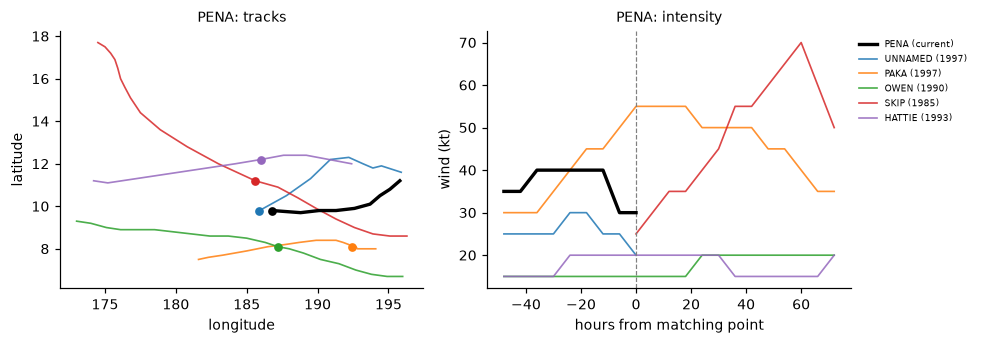

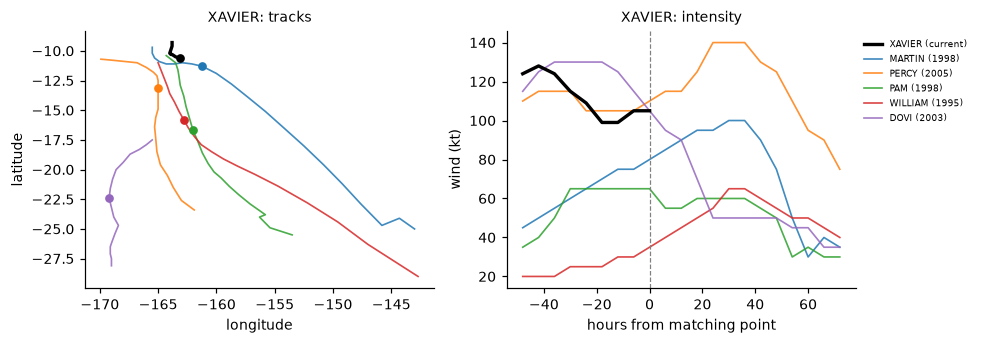

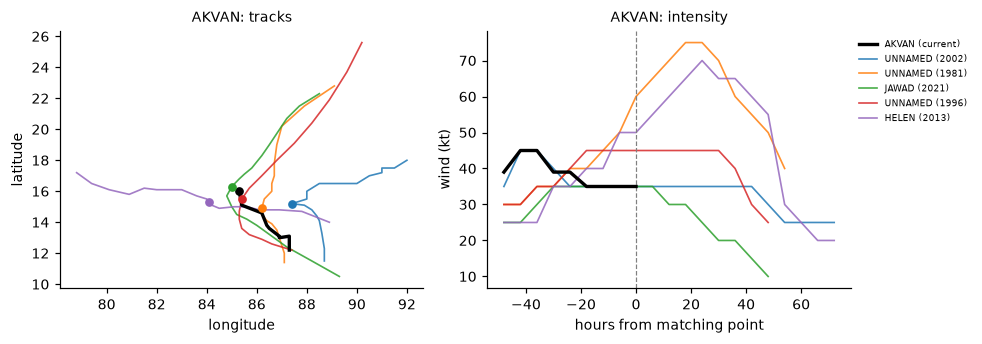

In [11]:
tr = story[story.section == "analog_tracks"]
storms = list(tr["storm_id"].dropna().unique())
if not storms:
    print("No analog tracks in this run.")
for sid in storms:
    t = tr[tr.storm_id == sid].copy()
    name = t["storm_name"].dropna().iloc[0] if t["storm_name"].notna().any() else sid
    if t["longitude"].max() - t["longitude"].min() > 180:          # track crosses 180°: plot in 0-360
        t["longitude"] = t["longitude"] % 360
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
    for rank, g in t.groupby("rank"):
        g = g.sort_values("offset_h")
        cur = rank == 0
        lbl = g["item_name"].iloc[0]
        kw = dict(color="black", lw=2.2, zorder=5) if cur else dict(lw=1.1, alpha=0.85)
        a1.plot(g["longitude"], g["latitude"], label=lbl, **kw)
        m = g[g.offset_h == 0]
        a1.scatter(m["longitude"], m["latitude"], s=22, zorder=6, color="black" if cur else None)
        a2.plot(g["offset_h"], g["value"], label=lbl, **kw)
    a2.axvline(0, color="grey", lw=0.8, ls="--")
    a1.set_xlabel("longitude"); a1.set_ylabel("latitude"); a1.set_title(f"{name}: tracks", fontsize=9)
    a2.set_xlabel("hours from matching point"); a2.set_ylabel("wind (kt)"); a2.set_title(f"{name}: intensity", fontsize=9)
    a2.legend(fontsize=6, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    save(fig, f"g3_analogs_{name}.png")

### 2.5 Alerts, source comparison and basin climatology (US-01, US-04, US-08)

In [12]:
display(story[story.section == "gdacs_alerts"].pivot_table(
    index=["storm_name", "item_id", "timestamp_utc"], columns="metric", values="value", aggfunc="first").round(1))
display(story[story.section == "source_comparison"].pivot_table(index="storm_name", columns="metric", values="value").round(1))
bc = story[story.section == "basin_climatology"].assign(
    storm_name=lambda d: d.storm_name.fillna("(whole basin)"))
display(bc.pivot_table(index=["basin", "storm_name"], columns="metric", values="value", aggfunc="first").round(1))

metric                                        alert_score  peak_wind_kt
storm_name item_id timestamp_utc                                       
AKVAN      1       2026-11-16 18:00:00+00:00          2.0          50.0
           10      2026-11-19 00:00:00+00:00          2.0          45.0
           13      2026-11-19 18:00:00+00:00          1.0          45.0
           5       2026-11-17 18:00:00+00:00          2.0          50.0
           6       2026-11-18 00:00:00+00:00          2.0          45.0
CEMPAKA    22      2026-11-11 12:00:00+00:00          1.0          95.0
PENA       24      2026-11-12 15:00:00+00:00          1.0          50.0
XAVIER     10      2026-11-19 18:00:00+00:00          1.0         130.0
           11      2026-11-20 00:00:00+00:00          1.0         130.0
           12      2026-11-20 06:00:00+00:00          1.0         130.0
           15      2026-11-21 00:00:00+00:00          1.0         130.0
           4       2026-11-16 18:00:00+00:00          1.0         120.0
           6       2026-11-17 18:00:00+00:00          1.0         130.0
           8       2026-11-18 18:00:00+00:00          1.0         130.0

metric,gdacs_lead_h,gdacs_peak_wind_kt,ibtracs_max_wind_kt,peak_difference_kt
storm_name,,,,
AKVAN,6.0,50.0,45.0,5.0
CEMPAKA,0.0,95.0,93.0,2.0
PENA,3.0,50.0,50.0,-0.0
XAVIER,36.0,130.0,128.0,2.0


metric               current_max_wind_percentile_in_basin  median_lifetime_max_wind_kt  share_active_in_current_month_pct  share_reaching_64kt_pct  storms_per_season
basin storm_name                                                                                                                                                     
EP    (whole basin)                                   NaN                         55.0                                4.8                     44.0               24.5
      PENA                                           44.5                          NaN                                NaN                      NaN                NaN
NI    (whole basin)                                   NaN                         35.0                               20.3                     19.4               10.0
      AKVAN                                          68.6                          NaN                                NaN                      NaN                NaN
SP    (whole basin)                                   NaN                         55.0                                4.0                     41.8               11.0
      XAVIER                                         94.9                          NaN                                NaN                      NaN                NaN

## 3. The same Gold folder read with PySpark
Spark reads each table as a folder of Parquet files; both tables share the `gold_run_ts` column, so the history of
KPIs can be queried across runs.

In [13]:
try:
    from tcmon.gold.spark import get_spark
    spark = get_spark("gold-preview")
    g = spark.read.parquet(*[str(f) for f in gov_files])
    g.groupBy("gold_run_ts", "status").count().orderBy("gold_run_ts", "status").show(30, truncate=False)
    s = spark.read.parquet(*[str(f) for f in story_files])
    s.filter("section = 'analogs' AND metric = 'sas'").select("gold_run_ts", "storm_name", "rank", "item_name", "value") \
     .orderBy("gold_run_ts", "storm_name", "rank").show(30, truncate=False)
    spark.stop()
except ImportError as exc:
    print("PySpark is not installed here; run this notebook inside the Airflow container.", exc)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/21 04:03:18 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/21 04:03:18 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


+---------------+------+-----+
|gold_run_ts    |status|count|
+---------------+------+-----+
|20261119_224000|fail  |15   |
|20261119_224000|info  |66   |
|20261119_224000|ok    |56   |
|20261119_224000|warn  |2    |
|20261119_232951|fail  |15   |
|20261119_232951|info  |67   |
|20261119_232951|ok    |56   |
|20261119_232951|warn  |2    |
|20261119_234000|fail  |15   |
|20261119_234000|info  |67   |
|20261119_234000|ok    |56   |
|20261119_234000|warn  |2    |
|20261120_004000|fail  |18   |
|20261120_004000|info  |68   |
|20261120_004000|ok    |56   |
|20261120_004000|warn  |1    |
|20261120_010035|fail  |18   |
|20261120_010035|info  |68   |
|20261120_010035|ok    |56   |
|20261120_010035|warn  |1    |
|20261120_010856|fail  |18   |
|20261120_010856|info  |69   |
|20261120_010856|ok    |56   |
|20261120_010856|warn  |1    |
|20261120_013215|fail  |17   |
|20261120_013215|info  |70   |
|20261120_013215|ok    |56   |
|20261120_013215|warn  |1    |
|20261120_014000|fail  |17   |
|2026112

+---------------+----------+----+-----------------+------------------+
|gold_run_ts    |storm_name|rank|item_name        |value             |
+---------------+----------+----+-----------------+------------------+
|20261119_224000|NULL      |1   |ALCIDE (2019)    |70.34298077480673 |
|20261119_224000|NULL      |2   |BOURA (2003)     |62.61991405891736 |
|20261119_224000|NULL      |3   |UNNAMED (1992)   |57.638415710138425|
|20261119_224000|NULL      |4   |ATANG (2003)     |53.42276027097205 |
|20261119_224000|NULL      |5   |ANTOINETTE (1997)|49.28376582868427 |
|20261119_224000|AKVAN     |1   |UNNAMED (1988)   |74.8744293213824  |
|20261119_224000|AKVAN     |2   |UNNAMED (1985)   |64.46001287977661 |
|20261119_224000|AKVAN     |3   |UNNAMED (1998)   |62.73587232656298 |
|20261119_224000|AKVAN     |4   |GAJA (2018)      |60.96150598440566 |
|20261119_224000|AKVAN     |5   |UNNAMED (1984)   |57.324171360853626|
|20261119_224000|CEMPAKA   |1   |KEITH (1997)     |68.8641413180003  |
|20261